# SentraGrade: Conditional GAN + ResNet50 Grader, with ML Testing (TensorFlow / Keras)
**Lab Evaluation 2: GAN model with another deep learning model, plus testing aspects on the case-study product.**

**Problem Statement.** SentraGrade is an automated fruit and vegetable grading system that runs on a conveyor belt
(TR-6 dataset: Banana, Carrot, Guava, Indian Gooseberry, Mango, Tomato). The classes are heavily imbalanced
(Banana has 323 images, Tomato has 2244).

* **Model 1, Conditional GAN:** generates synthetic produce images for a chosen class (projection discriminator, conditional BatchNorm, DiffAugment, EMA; see section 2).
* **Model 2, ResNet50 grader:** the same backbone, freeze and preprocessing as the original SentraGrade supervised model.

**Testing aspects covered (2 tests):**

| # | Test | Testing category | What it answers |
|---|------|------------------|-----------------|
| T1 | **FID (Fréchet Inception Distance)**, overall and per class, with real-vs-real floor and untrained-G ceiling | Correctness / output quality of a generative model (no ground truth, so we compare distributions) | Do the generated images look like real produce, and is quality uniform across classes? |
| T2 | **Back-to-back testing (TSTR / TRTS / Real+Synthetic)** on the same held-out real test set | Back-to-back testing from the ML-testing guide + downstream utility / synthetic-data fidelity | Is the synthetic data useful to the actual product model, and does adding it help or hurt? |

Each test has an explicit **acceptance criterion** and prints PASS/FAIL at the end.

**Why a conditional GAN?** Every downstream test needs labelled images: per-class FID, TSTR, TRTS and class-balanced
augmentation. A cGAN gives labelled samples from one model, where an unconditional GAN would need six separate models.

## Setup

In [1]:
import os, glob, json, time, random, zipfile, gc
from pathlib import Path

import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from PIL import Image
from scipy import linalg
from sklearn.model_selection import GroupShuffleSplit
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import accuracy_score, f1_score, recall_score, confusion_matrix
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore", category=linalg.LinAlgWarning)

# QUICK=True is a tiny smoke run that finishes in a few minutes. Use False for real results.
QUICK = False

SEED = 42
def set_seed(s):
    random.seed(s); np.random.seed(s); keras.utils.set_random_seed(s)
set_seed(SEED)

gpus = tf.config.list_physical_devices("GPU")
if gpus:
    # use exactly one GPU: on Kaggle "GPU T4 x2" a two-GPU TensorFlow session can hang at shutdown
    tf.config.set_visible_devices(gpus[0], "GPU")
    try: tf.config.experimental.set_memory_growth(gpus[0], True)
    except Exception: pass
print("TensorFlow", tf.__version__, "| Keras", keras.__version__,
      "| using GPU:", tf.config.get_visible_devices("GPU") or "NONE: set Accelerator to GPU in the Kaggle settings panel")

OUT = Path("/kaggle/working/gan_testing") if Path("/kaggle/working").exists() else Path("gan_testing_outputs")
OUT.mkdir(parents=True, exist_ok=True)

def log(msg):
    # print + append to OUT/progress.log, so long runs can be followed from outside the notebook
    print(msg, flush=True)
    with open(OUT / "progress.log", "a") as fh:
        fh.write(msg + "\n")

# ---- hyper-parameters ----
IMG = 64              # GAN resolution
NZ = 128              # latent size
GAN_EPOCHS = 2 if QUICK else 200
GAN_BS = 64
FID_EVERY = 1 if QUICK else 20
CLS_EPOCHS = 1 if QUICK else 5
CLS_SEEDS = [0] if QUICK else [0, 1]      # repeated runs give mean ± std for the back-to-back comparison
CLS_RES = 128

TensorFlow 2.20.0 | Keras 3.13.2 | using GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 1. Data
Upload `sentragrade_data.zip` (contains `resized/<Class>/*.jpg` and `manifest_full.csv`) as a Kaggle dataset and attach it
(right panel, **Add Input**). The cell below finds it anywhere under `/kaggle/input`. If Kaggle kept it as a `.zip`, the cell extracts it.

**Leakage-safe split.** Photos of the same fruit on the same day are near-duplicates, so we split by
`group_id` (class + day). No day appears in both train and test.

In [2]:
SEARCH_BASES = ["/kaggle/input", "/kaggle/working", str(Path("~/sentragrade_data").expanduser()), ".", ".."]

def _search_manifest():
    for base in SEARCH_BASES:
        if not os.path.isdir(base):
            continue
        for dirpath, dirnames, filenames in os.walk(base, followlinks=True):
            if "manifest_full.csv" in filenames and os.path.isdir(os.path.join(dirpath, "resized")):
                return Path(dirpath)
    return None

def find_data_root():
    root = _search_manifest()
    if root:
        return root
    # Kaggle sometimes keeps an uploaded .zip un-extracted, so unzip it ourselves
    for base in SEARCH_BASES:
        for z in glob.glob(f"{base}/**/*.zip", recursive=True):
            with zipfile.ZipFile(z) as zf:
                if any(n.endswith("manifest_full.csv") for n in zf.namelist()):
                    dest = Path("/kaggle/working/sentragrade_data") if Path("/kaggle/working").exists() else Path("sentragrade_data")
                    print(f"Extracting {z} -> {dest}")
                    zf.extractall(dest)
                    SEARCH_BASES.insert(0, str(dest))
                    root = _search_manifest()
                    if root:
                        return root
    print("Contents of /kaggle/input:")
    for i, (dirpath, dirnames, filenames) in enumerate(os.walk("/kaggle/input", followlinks=True)):
        print(" ", dirpath, "| dirs:", dirnames[:6], "| files:", filenames[:4])
        if i >= 40: break
    raise FileNotFoundError("manifest_full.csv + resized/ not found. Attach the dataset made from sentragrade_data.zip "
                            "(right panel -> Add Input), then re-run this cell.")

DATA_ROOT = find_data_root()
print("DATA_ROOT =", DATA_ROOT)

man = pd.read_csv(DATA_ROOT / "manifest_full.csv")
man["path"] = [str(DATA_ROOT / "resized" / c / f) for c, f in zip(man.class_name, man.filename)]
man = man[man.path.map(os.path.exists)].drop_duplicates(["class_name", "filename"]).reset_index(drop=True)

CLASSES = sorted(man.class_name.unique())
NC = len(CLASSES)
cls2idx = {c: i for i, c in enumerate(CLASSES)}
man["y"] = man.class_name.map(cls2idx)

# per-class group split so every class appears in the test set
parts = []
for c, d in man.groupby("class_name"):
    gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
    tr, te = next(gss.split(d, groups=d.group_id))
    d = d.copy(); d["split"] = "train"; d.iloc[te, d.columns.get_loc("split")] = "test"
    parts.append(d)
man = pd.concat(parts).reset_index(drop=True)
if QUICK:
    man = man.groupby(["class_name", "split"]).head(40).reset_index(drop=True)

assert not set(man[man.split == "train"].group_id) & set(man[man.split == "test"].group_id), "group leakage!"
print(pd.crosstab(man.class_name, man.split, margins=True))

DATA_ROOT = /kaggle/input/datasets/riteesh23f3002667/sentragrade-data
split              test  train   All
class_name                          
Banana              102    221   323
Carrot              102    356   458
Guava               102    408   510
Indian_Gooseberry   289   1122  1411
Mango                85    307   392
Tomato              459   1785  2244
All                1139   4199  5338


train (4199, 64, 64, 3)  test (1139, 64, 64, 3)  (26s)


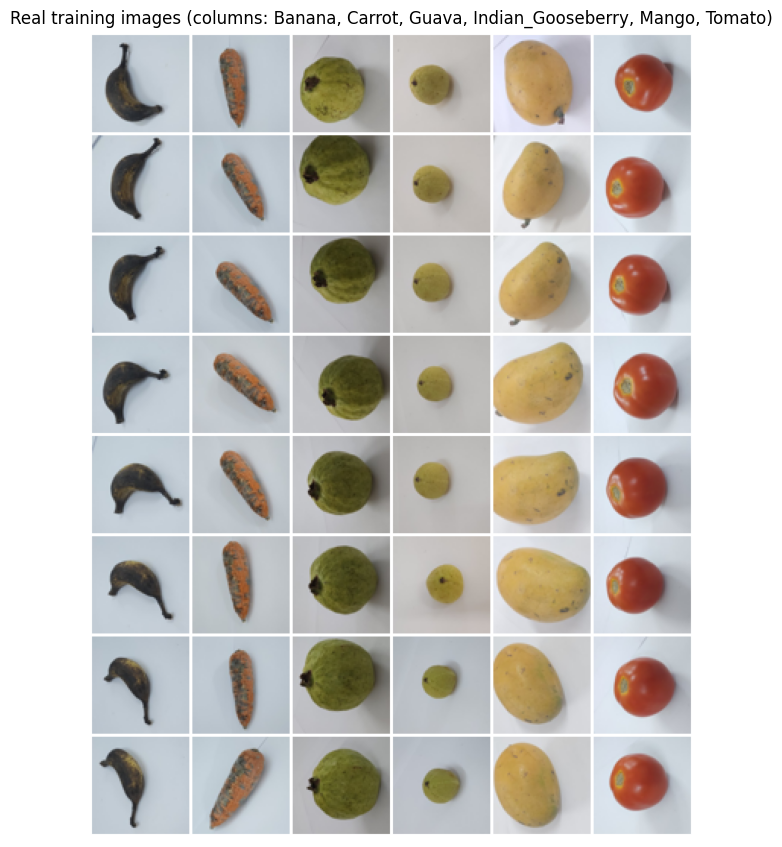

In [3]:
def load_img(p, size=IMG):
    im = Image.open(p).convert("RGB")
    w, h = im.size; s = min(w, h)
    im = im.crop(((w - s) // 2, (h - s) // 2, (w - s) // 2 + s, (h - s) // 2 + s)).resize((size, size), Image.BICUBIC)
    return np.asarray(im)

def to_arrays(df):
    x = np.stack([load_img(p) for p in df.path]).astype("float32") / 127.5 - 1.0   # N,H,W,3 in [-1, 1]
    return x, df.y.values.astype("int32")

t0 = time.time()
Xtr, ytr = to_arrays(man[man.split == "train"])
Xte, yte = to_arrays(man[man.split == "test"])
print(f"train {Xtr.shape}  test {Xte.shape}  ({time.time()-t0:.0f}s)")

def show_grid(x, ncol, title, fname=None, pad=2):
    x = (np.clip(x, -1, 1) + 1) / 2
    nrow = int(np.ceil(len(x) / ncol)); H = IMG + pad
    canvas = np.ones((nrow * H + pad, ncol * H + pad, 3))
    for i, im in enumerate(x):
        r, c = divmod(i, ncol)
        canvas[pad + r * H: pad + r * H + IMG, pad + c * H: pad + c * H + IMG] = im
    plt.figure(figsize=(ncol * 1.3, nrow * 1.3 + 0.4)); plt.imshow(canvas); plt.axis("off"); plt.title(title)
    if fname: plt.savefig(OUT / fname, bbox_inches="tight", dpi=120)
    plt.show()

# real samples, 8 per class (one column per class)
idx = [np.where(ytr == c)[0][r] for r in range(8) for c in range(NC)]
show_grid(Xtr[idx], NC, "Real training images (columns: " + ", ".join(CLASSES) + ")", "real_samples.png")

## 2. Model 1: Conditional GAN (Keras)
Each design choice below addresses a known failure mode of GANs trained on small, imbalanced datasets like TR-6:

| Design choice | Why |
|---|---|
| **Conditional BatchNorm** in G (class-specific scale and shift at every layer) | Strong class conditioning, so each fruit keeps its own colour and shape |
| **Projection discriminator** (Miyato & Koyama, 2018) | D judges both realism *and* whether the image matches its label |
| **Spectral normalisation** in D + **hinge loss** + TTUR learning rates (D 4e-4, G 1e-4, Adam β = (0, 0.9)) | Stable adversarial training |
| **DiffAugment** (translation + cutout) on real *and* fake images before D (Zhao et al., 2020) | Stops D from overfitting the ~4k training images. No colour jitter, because colour is what separates the classes |
| **EMA generator** (exponential moving average of G's weights, decay 0.999) | Smoother, higher-quality samples. Used for all sampling and evaluation |
| **Class-balanced sampling** | Minority classes (Banana, Mango) are seen as often as Tomato. Minority modes are usually the first ones a GAN loses |

In [4]:
INIT = keras.initializers.RandomNormal(0.0, 0.02)

def SN(layer):
    # Keras >= 2.13 / Keras 3 ship SpectralNormalization; fall back to a plain layer if missing
    return layers.SpectralNormalization(layer) if hasattr(layers, "SpectralNormalization") else layer

class ConditionalBatchNorm(layers.Layer):
    # BatchNorm whose scale and shift are looked up per class: h_norm * (1 + gamma[y]) + beta[y]
    def __init__(self, channels, num_classes, **kwargs):
        super().__init__(**kwargs)
        self.channels, self.num_classes = channels, num_classes
        self.bn = layers.BatchNormalization(momentum=0.9, center=False, scale=False)
        self.gamma = layers.Embedding(num_classes, channels, embeddings_initializer="zeros")
        self.beta = layers.Embedding(num_classes, channels, embeddings_initializer="zeros")

    def call(self, h, y, training=None):
        h = self.bn(h, training=training)
        g = tf.reshape(self.gamma(y), (-1, 1, 1, self.channels))
        b = tf.reshape(self.beta(y), (-1, 1, 1, self.channels))
        return h * (1.0 + g) + b

    def get_config(self):
        return {**super().get_config(), "channels": self.channels, "num_classes": self.num_classes}

def build_generator(ngf=64, emb=64):
    z = keras.Input((NZ,), name="z")
    y = keras.Input((1,), dtype="int32", name="label")
    e = layers.Flatten()(layers.Embedding(NC, emb)(y))
    h = layers.Dense(4 * 4 * ngf * 8, kernel_initializer=INIT)(layers.Concatenate()([z, e]))
    h = layers.Reshape((4, 4, ngf * 8))(h)
    h = layers.ReLU()(ConditionalBatchNorm(ngf * 8, NC)(h, y))
    for f in [ngf * 4, ngf * 2, ngf]:                                   # 8 -> 16 -> 32
        h = layers.Conv2DTranspose(f, 4, 2, padding="same", use_bias=False, kernel_initializer=INIT)(h)
        h = layers.ReLU()(ConditionalBatchNorm(f, NC)(h, y))
    out = layers.Conv2DTranspose(3, 4, 2, padding="same", activation="tanh", kernel_initializer=INIT)(h)  # 64
    return keras.Model([z, y], out, name="generator")

def build_discriminator(ndf=64):
    # projection discriminator: logit = w . phi(x) + <embed(y), phi(x)>
    x = keras.Input((IMG, IMG, 3), name="image")
    y = keras.Input((1,), dtype="int32", name="label")
    h = x
    for f in [ndf, ndf * 2, ndf * 4, ndf * 8]:                          # 32 -> 16 -> 8 -> 4
        h = layers.LeakyReLU(0.2)(SN(layers.Conv2D(f, 4, 2, padding="same", kernel_initializer=INIT))(h))
    phi = layers.Lambda(lambda t: tf.reduce_sum(t, axis=[1, 2]), name="sum_pool")(h)   # sum pooling (SNGAN)
    unconditional = SN(layers.Dense(1, kernel_initializer=INIT))(phi)
    class_emb = layers.Flatten()(layers.Embedding(NC, ndf * 8)(y))
    projection = layers.Dot(axes=1)([class_emb, phi])
    return keras.Model([x, y], layers.Flatten()(layers.Add()([unconditional, projection])), name="discriminator")

def diff_augment(x):
    # DiffAugment "translation,cutout" (Zhao et al., 2020): differentiable, applied to real AND fake before D
    B = tf.shape(x)[0]
    pad = IMG // 8
    xp = tf.pad(x, [[0, 0], [pad, pad], [pad, pad], [0, 0]])
    sy = tf.random.uniform((B,), 0, 2 * pad + 1, dtype=tf.int32)
    sx = tf.random.uniform((B,), 0, 2 * pad + 1, dtype=tf.int32)
    rows = sy[:, None] + tf.range(IMG)[None, :]
    cols = sx[:, None] + tf.range(IMG)[None, :]
    x = tf.gather(tf.gather(xp, rows, axis=1, batch_dims=1), cols, axis=2, batch_dims=1)
    half = IMG // 4                                                      # cutout square of side IMG/2
    cy = tf.random.uniform((B, 1, 1), 0, IMG, dtype=tf.int32)
    cx = tf.random.uniform((B, 1, 1), 0, IMG, dtype=tf.int32)
    r = tf.range(IMG)[None, :, None]; c = tf.range(IMG)[None, None, :]
    keep = tf.logical_not((tf.abs(r - cy) < half) & (tf.abs(c - cx) < half))
    return x * tf.cast(keep, x.dtype)[..., None]

def generate(G, labels, bs=250):
    labels = np.asarray(labels, dtype="int32")
    out = []
    for i in range(0, len(labels), bs):
        y = tf.constant(labels[i:i + bs, None])
        z = tf.random.normal((len(y), NZ))
        out.append(G([z, y], training=False).numpy())
    return np.concatenate(out)

G = build_generator()
G_ema = build_generator()          # exponential moving average of G's weights, used for all evaluation
G_ema.set_weights(G.get_weights())
D = build_discriminator()
print(f"G params: {G.count_params()/1e6:.2f}M | D params: {D.count_params()/1e6:.2f}M")

I0000 00:00:1791658773.949280      24 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5


G params: 4.35M | D params: 2.76M


## 3. FID utilities (used by Test T1 and for checkpoint selection)
FID = ‖μ_r − μ_g‖² + Tr(Σ_r + Σ_g − 2(Σ_r Σ_g)^{1/2}) on 2048-d **Keras InceptionV3** pool features. **Lower is better.**
The reference set is the real *training* images. Every FID we compare uses the same sample size N,
because FID is biased by N.

In [5]:
try:
    inception = keras.applications.InceptionV3(include_top=False, pooling="avg", weights="imagenet", input_shape=(299, 299, 3))
except Exception as e:
    raise RuntimeError("Could not download InceptionV3 weights. In Kaggle turn ON 'Internet' in the notebook settings.") from e
inception.trainable = False

@tf.function(reduce_retracing=True)
def _inc(b):
    # our images are already in [-1, 1], which is exactly what inception_v3.preprocess_input produces
    return inception(tf.image.resize(b, (299, 299)), training=False)

def inception_feats(x, bs=100):
    return np.concatenate([_inc(tf.constant(x[i:i + bs])).numpy() for i in range(0, len(x), bs)]).astype(np.float64)

def fid(f1, f2):
    mu1, mu2 = f1.mean(0), f2.mean(0)
    s1, s2 = np.cov(f1, rowvar=False), np.cov(f2, rowvar=False)
    # Tr((S1 S2)^1/2) = sum of sqrt(eigenvalues of S1 S2): same value as scipy.linalg.sqrtm, ~4x faster
    with np.errstate(all="ignore"):
        eig = np.linalg.eigvals(s1 @ s2)
    tr_covmean = np.sqrt(np.clip(eig.real, 0, None)).sum()
    return float(((mu1 - mu2) ** 2).sum() + np.trace(s1) + np.trace(s2) - 2 * tr_covmean)

t0 = time.time()
feat_train = inception_feats(Xtr)
feat_test = inception_feats(Xte)
print(f"Inception features: train {feat_train.shape}, test {feat_test.shape} ({time.time()-t0:.0f}s)")

87910968/87910968 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
Inception features: train (4199, 2048), test (1139, 2048) (38s)


## 4. Train the GAN (custom `tf.GradientTape` loop, hinge loss + DiffAugment + EMA; tracks FID and keeps the best EMA checkpoint)

In [6]:
opt_G = keras.optimizers.Adam(1e-4, beta_1=0.0, beta_2=0.9)
opt_D = keras.optimizers.Adam(4e-4, beta_1=0.0, beta_2=0.9)
EMA_DECAY = 0.999

Xtr_tf = tf.constant(Xtr)
ytr_tf = tf.constant(ytr[:, None])

@tf.function
def train_step(batch_idx):
    xb = tf.gather(Xtr_tf, batch_idx)
    yb = tf.gather(ytr_tf, batch_idx)
    B = tf.shape(xb)[0]
    xb = tf.where(tf.random.uniform((B, 1, 1, 1)) < 0.5, tf.reverse(xb, axis=[2]), xb)   # random h-flip
    z = tf.random.normal((B, NZ))
    yf = tf.random.uniform((B, 1), 0, NC, dtype=tf.int32)

    with tf.GradientTape() as tape_D:
        fake = G([z, yf], training=True)
        d_real = D([diff_augment(xb), yb], training=True)
        d_fake = D([diff_augment(fake), yf], training=True)
        loss_D = tf.reduce_mean(tf.nn.relu(1.0 - d_real)) + tf.reduce_mean(tf.nn.relu(1.0 + d_fake))   # hinge
    opt_D.apply_gradients(zip(tape_D.gradient(loss_D, D.trainable_variables), D.trainable_variables))

    with tf.GradientTape() as tape_G:
        g_out = D([diff_augment(G([z, yf], training=True)), yf], training=True)
        loss_G = -tf.reduce_mean(g_out)
    opt_G.apply_gradients(zip(tape_G.gradient(loss_G, G.trainable_variables), G.trainable_variables))

    for w_ema, w in zip(G_ema.weights, G.weights):
        w_ema.assign(EMA_DECAY * w_ema + (1.0 - EMA_DECAY) * w)
    return loss_D, loss_G, tf.reduce_mean(d_real), tf.reduce_mean(d_fake)

# class-balanced sampling: each class is drawn equally often
counts = np.bincount(ytr, minlength=NC)
p_sample = (1.0 / counts)[ytr]; p_sample /= p_sample.sum()
steps_per_epoch = len(ytr) // GAN_BS

fixed_y = np.tile(np.arange(NC), 8).astype("int32")
fixed_z = tf.random.normal((len(fixed_y), NZ), seed=SEED)
hist = {"d_loss": [], "g_loss": [], "D(x)": [], "D(G(z))": []}
fid_hist, best_fid, best_G = [], float("inf"), None

t0 = time.time()
for ep in range(1, GAN_EPOCHS + 1):
    idx = np.random.choice(len(ytr), size=steps_per_epoch * GAN_BS, p=p_sample).astype("int32")
    s = np.zeros(4)
    for b in range(steps_per_epoch):
        s += np.array([v.numpy() for v in train_step(tf.constant(idx[b * GAN_BS:(b + 1) * GAN_BS]))])
    for k, v in zip(hist, s / steps_per_epoch): hist[k].append(float(v))

    if ep % 5 == 0 and ep % FID_EVERY != 0:
        log(f"epoch {ep:3d} | D {hist['d_loss'][-1]:.3f} G {hist['g_loss'][-1]:.3f} | {time.time()-t0:.0f}s")
    if ep % FID_EVERY == 0 or ep == GAN_EPOCHS:
        f = fid(inception_feats(generate(G_ema, yte)), feat_train)   # same N and class mix as the real test set
        fid_hist.append((ep, f))
        if f < best_fid:
            best_fid, best_G = f, [w.copy() for w in G_ema.get_weights()]
        log(f"epoch {ep:3d} | D {hist['d_loss'][-1]:.3f} G {hist['g_loss'][-1]:.3f} | "
            f"D(x) {hist['D(x)'][-1]:.2f} D(G(z)) {hist['D(G(z))'][-1]:.2f} | FID(EMA) {f:.1f} | {time.time()-t0:.0f}s")

G_ema.set_weights(best_G)
G_train = G
G = G_ema                          # every test below uses the best EMA generator
G.save(OUT / "generator_best.keras")
log(f"Best FID during training: {best_fid:.1f} (EMA checkpoint restored)")

epoch   5 | D 1.365 G 0.815 | 47s
epoch  10 | D 1.570 G 0.467 | 84s
epoch  15 | D 1.582 G 0.401 | 120s
epoch  20 | D 1.636 G 0.390 | D(x) 0.30 D(G(z)) -0.25 | FID(EMA) 359.9 | 168s
epoch  25 | D 1.682 G 0.365 | 204s
epoch  30 | D 1.740 G 0.361 | 241s
epoch  35 | D 1.700 G 0.368 | 277s
epoch  40 | D 1.733 G 0.324 | D(x) 0.21 D(G(z)) -0.18 | FID(EMA) 337.9 | 323s
epoch  45 | D 1.768 G 0.332 | 359s
epoch  50 | D 1.798 G 0.319 | 396s
epoch  55 | D 1.765 G 0.292 | 433s
epoch  60 | D 1.802 G 0.318 | D(x) 0.11 D(G(z)) -0.18 | FID(EMA) 256.6 | 479s
epoch  65 | D 1.814 G 0.264 | 516s
epoch  70 | D 1.834 G 0.284 | 552s
epoch  75 | D 1.835 G 0.231 | 589s
epoch  80 | D 1.862 G 0.246 | D(x) 0.07 D(G(z)) -0.12 | FID(EMA) 227.1 | 634s
epoch  85 | D 1.870 G 0.211 | 671s
epoch  90 | D 1.842 G 0.290 | 707s
epoch  95 | D 1.905 G 0.238 | 744s
epoch 100 | D 1.891 G 0.159 | D(x) 0.12 D(G(z)) -0.04 | FID(EMA) 216.5 | 790s
epoch 105 | D 1.890 G 0.216 | 826s
epoch 110 | D 1.895 G 0.188 | 863s
epoch 115 | D 1.8

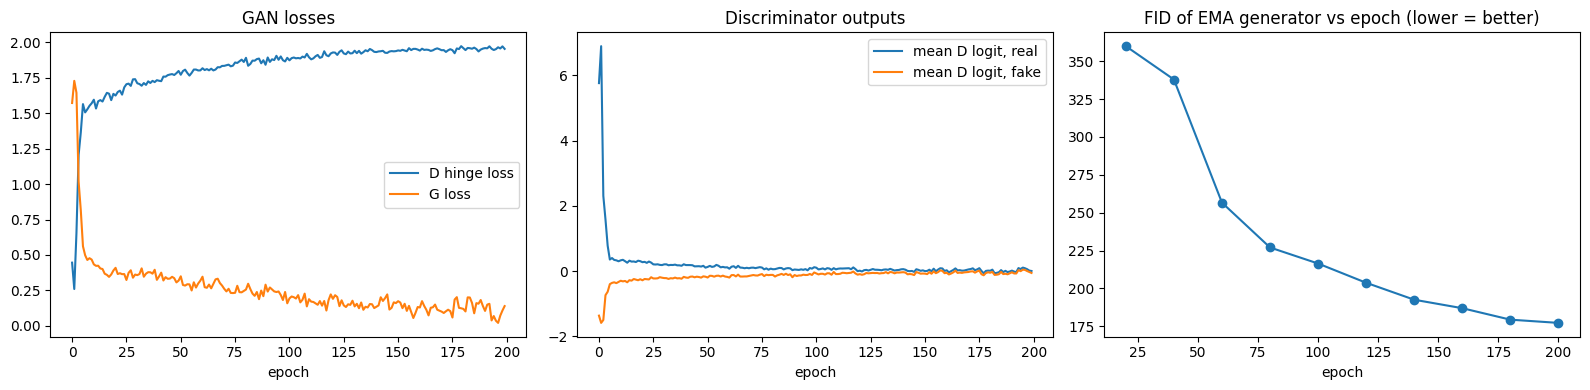

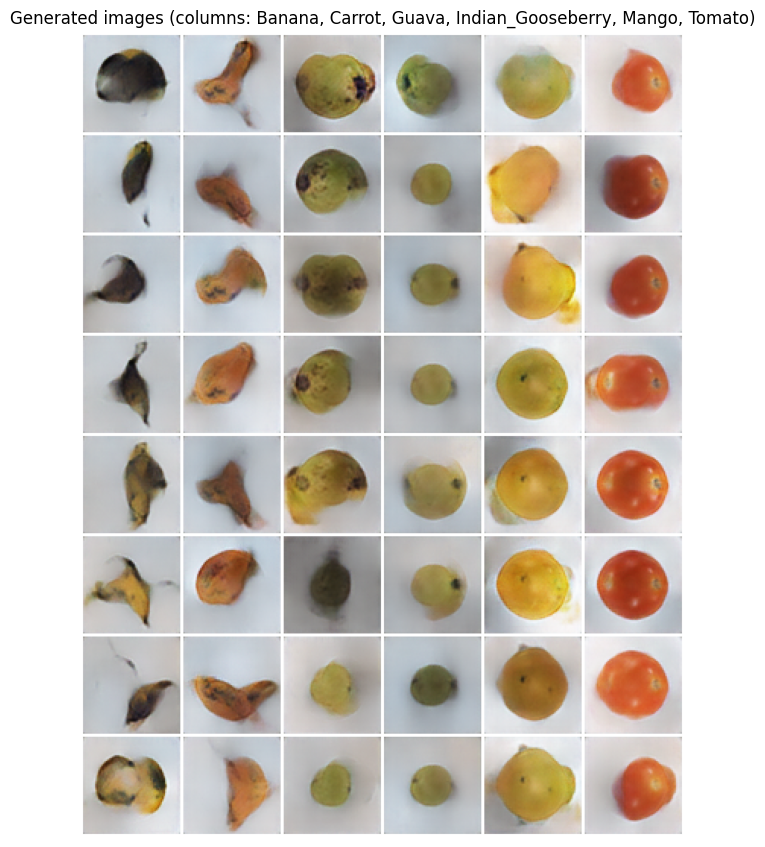

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].plot(hist["d_loss"], label="D hinge loss"); ax[0].plot(hist["g_loss"], label="G loss"); ax[0].set_title("GAN losses"); ax[0].legend()
ax[1].plot(hist["D(x)"], label="mean D logit, real"); ax[1].plot(hist["D(G(z))"], label="mean D logit, fake"); ax[1].set_title("Discriminator outputs"); ax[1].legend()
ax[2].plot(*zip(*fid_hist), "o-"); ax[2].set_title("FID of EMA generator vs epoch (lower = better)"); ax[2].set_xlabel("epoch")
for a in ax[:2]: a.set_xlabel("epoch")
plt.tight_layout(); plt.savefig(OUT / "gan_training_curves.png", dpi=120); plt.show()

fixed = G([fixed_z, tf.constant(fixed_y[:, None])], training=False).numpy()
show_grid(fixed, NC, "Generated images (columns: " + ", ".join(CLASSES) + ")", "generated_samples.png")

---
# TEST T1: Output correctness via FID
Generative models have no ground truth, so we test the **distribution**:

* **Floor (real vs real):** FID(real test, real train). This is the best FID achievable given dataset variation.
* **Model:** FID(generated, real train), using the same N and the same class mix as the test set.
* **Ceiling / oracle sanity check:** FID(untrained G, real train). If the metric can't separate this from the model, the test itself is broken.
* **Per-class FID:** shows whether quality is uniform across produce types (a bias check, since minority classes are often worse).

**Acceptance criteria:**
* T1a: FID_model < 0.5 × FID_untrained (the GAN learned a lot more than noise).
* T1b: worst-class FID ≤ 2 × best-class FID (no class is badly under-served).

== T1 overall FID ==


,setting,FID
0,Real test vs real train (floor),18.3
1,Trained cGAN vs real train,176.9
2,Untrained G vs real train (ceiling),413.9


== T1 per-class FID ==


,class,n_train,N,FID_real_floor,FID_generated,gap
0,Banana,221,102,180.1,304.8,124.6
1,Carrot,356,102,30.8,289.4,258.5
2,Guava,408,102,53.5,159.8,106.3
3,Indian_Gooseberry,1122,289,18.2,237.4,219.2
4,Mango,307,85,30.4,202.2,171.8
5,Tomato,1785,459,8.1,189.4,181.3


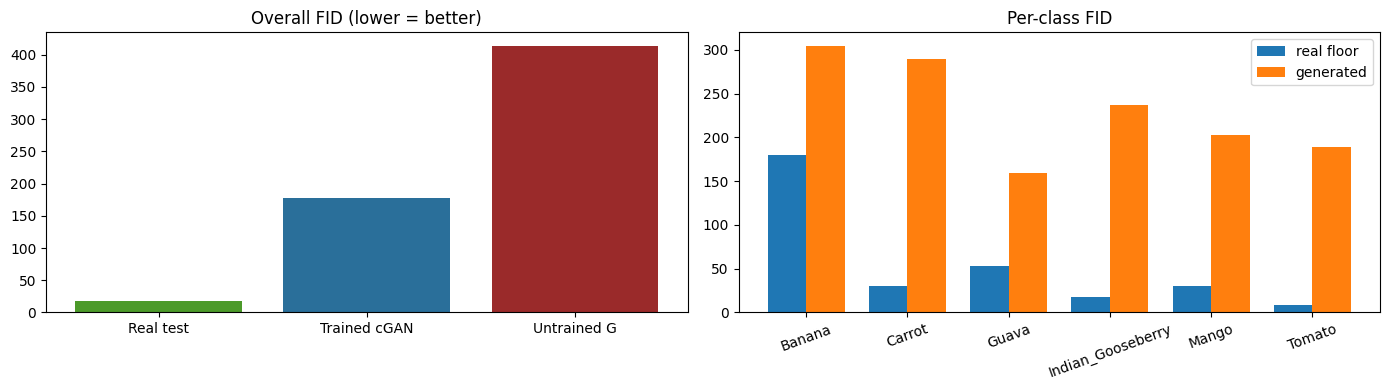

In [8]:
set_seed(SEED)
G_untrained = build_generator()

fid_floor = fid(feat_test, feat_train)
fid_model = fid(inception_feats(generate(G, yte)), feat_train)
fid_untrained = fid(inception_feats(generate(G_untrained, yte)), feat_train)

rows = []
for c, name in enumerate(CLASSES):
    ref = feat_train[ytr == c]
    n_c = int((yte == c).sum())
    f_real = fid(feat_test[yte == c], ref)
    f_gen = fid(inception_feats(generate(G, np.full(n_c, c))), ref)
    rows.append({"class": name, "n_train": int((ytr == c).sum()), "N": n_c,
                 "FID_real_floor": round(f_real, 1), "FID_generated": round(f_gen, 1), "gap": round(f_gen - f_real, 1)})
per_class_fid = pd.DataFrame(rows)

t1_overall = pd.DataFrame({"setting": ["Real test vs real train (floor)", "Trained cGAN vs real train", "Untrained G vs real train (ceiling)"],
                           "FID": [round(fid_floor, 1), round(fid_model, 1), round(fid_untrained, 1)]})
print("== T1 overall FID =="); display(t1_overall)
print("== T1 per-class FID =="); display(per_class_fid)

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].bar(t1_overall.setting.str.split(" vs").str[0], t1_overall.FID, color=["#4c9a2a", "#2a6f9a", "#9a2a2a"])
ax[0].set_title("Overall FID (lower = better)")
w = 0.38; xs = np.arange(NC)
ax[1].bar(xs - w/2, per_class_fid.FID_real_floor, w, label="real floor")
ax[1].bar(xs + w/2, per_class_fid.FID_generated, w, label="generated")
ax[1].set_xticks(xs); ax[1].set_xticklabels(CLASSES, rotation=20); ax[1].set_title("Per-class FID"); ax[1].legend()
plt.tight_layout(); plt.savefig(OUT / "t1_fid.png", dpi=120); plt.show()

T1a = fid_model < 0.5 * fid_untrained
T1b = per_class_fid.FID_generated.max() <= 2 * per_class_fid.FID_generated.min()

---
# Model 2: ResNet50 grader (the product's classifier)
This matches the original SentraGrade supervised model (`supervised_ood_eval_gradcam_tf.ipynb`):
* `keras.applications.ResNet50` (ImageNet) with `resnet50.preprocess_input` (RGB→BGR + mean subtraction)
* **Frozen:** `conv1`, `pool1`, `conv2_block*`, `conv3_block*` (stem + layer1 + layer2). **Fine-tuned:** `conv4_block*`, `conv5_block*` + new 6-way head
* AdamW (lr 1e-4, weight decay 1e-4) with cosine decay, and balanced class weights

The GAN works at 64 px, so every image (real or synthetic) is upsampled to 128 px inside the model. Every variant uses
identical hyper-parameters and seeds, so **the training data is the only thing that changes**.

In [9]:
FROZEN_PREFIXES = ("conv1", "pool1", "conv2_block", "conv3_block")

def make_classifier():
    inp = keras.Input((IMG, IMG, 3))                               # images in [-1, 1]
    x = layers.Resizing(CLS_RES, CLS_RES)(inp)
    x = layers.Rescaling(127.5, offset=127.5)(x)                   # -> [0, 255]
    x = layers.Lambda(keras.applications.resnet50.preprocess_input)(x)
    try:
        base = keras.applications.ResNet50(weights="imagenet", include_top=False, input_tensor=x)
    except Exception:
        print("WARNING: no internet, ResNet50 trains from scratch")
        base = keras.applications.ResNet50(weights=None, include_top=False, input_tensor=x)
    for layer in base.layers:
        layer.trainable = not layer.name.startswith(FROZEN_PREFIXES)
    pooled = layers.GlobalAveragePooling2D(name="pooled_features")(base.output)
    logits = layers.Dense(NC, name="logits")(pooled)
    return keras.Model(inp, logits, name="resnet50_grader")

def train_classifier(X, y, seed, batch_size=64):
    set_seed(seed)
    m = make_classifier()
    steps = CLS_EPOCHS * (len(X) // batch_size)
    m.compile(optimizer=keras.optimizers.AdamW(keras.optimizers.schedules.CosineDecay(1e-4, max(steps, 1)), weight_decay=1e-4),
              loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True), metrics=["accuracy"],
              jit_compile=False)   # skip XLA: compiling ResNet50 for every run costs more than it saves here
    present = np.unique(y)
    cw = dict(zip(present.tolist(), compute_class_weight("balanced", classes=present, y=y).tolist()))
    ds = (tf.data.Dataset.from_tensor_slices((X, y)).shuffle(len(X), seed=seed)
          .batch(batch_size, drop_remainder=True)
          .map(lambda a, b: (tf.image.random_flip_left_right(a), b), num_parallel_calls=tf.data.AUTOTUNE)
          .prefetch(tf.data.AUTOTUNE))
    m.fit(ds, epochs=CLS_EPOCHS, class_weight=cw, shuffle=False, verbose=2)  # ds is already shuffled
    return m

def predict(m, X):
    return m.predict(X, batch_size=256, verbose=0).argmax(1)

def scores(y_true, y_pred):
    return {"acc": accuracy_score(y_true, y_pred), "macro_f1": f1_score(y_true, y_pred, average="macro"),
            **{f"recall_{c}": r for c, r in zip(CLASSES, recall_score(y_true, y_pred, average=None, labels=range(NC), zero_division=0))}}

_m = make_classifier()
print(f"ResNet50 grader: {_m.count_params()/1e6:.1f}M params, "
      f"{sum(int(np.prod(v.shape)) for v in _m.trainable_weights)/1e6:.1f}M trainable (frozen up to conv3_block*)")
del _m; _ = gc.collect()

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step
ResNet50 grader: 23.6M params, 22.1M trainable (frozen up to conv3_block*)


---
# TEST T2: Back-to-back testing / downstream utility
Same model, same seeds, same **real held-out test set**. Only the training data differs:

| Variant | Train on | Test on | Meaning |
|---|---|---|---|
| **TRTR** | Real | Real | Baseline grader |
| **TSTR** | Synthetic only (same size and class mix as real) | Real | Does the GAN capture the features that matter for grading? |
| **TRTS** | Real | Synthetic | Are generated images recognisable as their class? (conditional correctness) |
| **R+S** | Real + class-balanced synthetic | Real | Product use case: GAN augmentation for minority classes |

**Acceptance criteria:**
* T2a: TSTR accuracy ≥ 0.70 × TRTR accuracy (synthetic-data utility ratio)
* T2b: TRTS accuracy ≥ 0.70 (generated images carry the correct class)
* T2c: macro-F1(R+S) ≥ macro-F1(TRTR) − 0.01 (augmentation must not regress the product)

In [10]:
set_seed(SEED)
Xsyn, ysyn = generate(G, ytr), ytr.copy()                         # TSTR set: mirrors real train
y_bal = np.repeat(np.arange(NC), len(ytr) // NC).astype("int32")
X_aug, y_aug = np.concatenate([Xtr, generate(G, y_bal)]), np.concatenate([ytr, y_bal])
y_trts = np.repeat(np.arange(NC), max(len(yte) // NC, 1)).astype("int32")   # TRTS set: balanced synthetic test set
X_trts = generate(G, y_trts)

results, preds_store = [], {}
t0 = time.time()
for seed in CLS_SEEDS:
    log(f"--- seed {seed}: TRTR ---")
    m = train_classifier(Xtr, ytr, seed)
    p = predict(m, Xte);    results.append({"variant": "TRTR", "seed": seed, **scores(yte, p)}); preds_store[("TRTR", seed)] = p
    p = predict(m, X_trts); results.append({"variant": "TRTS", "seed": seed, **scores(y_trts, p)})
    del m; gc.collect()

    log(f"--- seed {seed}: TSTR ---")
    m = train_classifier(Xsyn, ysyn, seed)
    p = predict(m, Xte);    results.append({"variant": "TSTR", "seed": seed, **scores(yte, p)}); preds_store[("TSTR", seed)] = p
    del m; gc.collect()

    log(f"--- seed {seed}: R+S ---")
    m = train_classifier(X_aug, y_aug, seed)
    p = predict(m, Xte);    results.append({"variant": "R+S", "seed": seed, **scores(yte, p)}); preds_store[("R+S", seed)] = p
    del m; gc.collect()
    log(f"seed {seed} done ({time.time()-t0:.0f}s)")

res = pd.DataFrame(results)
order = ["TRTR", "TSTR", "TRTS", "R+S"]
summary = res.groupby("variant").agg(["mean", "std"]).drop(columns="seed").reindex(order)
display(summary[["acc", "macro_f1"]].round(4))
print("Per-class recall (mean over seeds): checks whether minority classes benefit")
display(res.groupby("variant")[[f"recall_{c}" for c in CLASSES]].mean().reindex(order).round(3))

--- seed 0: TRTR ---
Epoch 1/5
65/65 - 37s - 564ms/step - accuracy: 0.9707 - loss: 0.0980
Epoch 2/5
65/65 - 13s - 204ms/step - accuracy: 1.0000 - loss: 5.4355e-04
Epoch 3/5
65/65 - 13s - 200ms/step - accuracy: 1.0000 - loss: 2.3451e-04
Epoch 4/5
65/65 - 13s - 196ms/step - accuracy: 1.0000 - loss: 1.4069e-04
Epoch 5/5
65/65 - 13s - 195ms/step - accuracy: 1.0000 - loss: 1.4454e-04
--- seed 0: TSTR ---
Epoch 1/5
65/65 - 35s - 532ms/step - accuracy: 0.9632 - loss: 0.1459
Epoch 2/5
65/65 - 13s - 202ms/step - accuracy: 0.9998 - loss: 0.0022
Epoch 3/5
65/65 - 13s - 204ms/step - accuracy: 1.0000 - loss: 0.0012
Epoch 4/5
65/65 - 13s - 200ms/step - accuracy: 0.9998 - loss: 9.5680e-04
Epoch 5/5
65/65 - 13s - 197ms/step - accuracy: 1.0000 - loss: 5.6234e-04
--- seed 0: R+S ---
Epoch 1/5
131/131 - 47s - 362ms/step - accuracy: 0.9782 - loss: 0.0689
Epoch 2/5
131/131 - 26s - 201ms/step - accuracy: 0.9994 - loss: 0.0029
Epoch 3/5
131/131 - 26s - 196ms/step - accuracy: 0.9998 - loss: 0.0012
Epoch 4/5
1

acc         macro_f1        
           mean     std     mean     std
variant                                 
TRTR     1.0000  0.0000   1.0000  0.0000
TSTR     0.9789  0.0037   0.9562  0.0101
TRTS     0.8404  0.0387   0.8189  0.0536
R+S      1.0000  0.0000   1.0000  0.0000

Per-class recall (mean over seeds): checks whether minority classes benefit


,recall_Banana,recall_Carrot,recall_Guava,recall_Indian_Gooseberry,recall_Mango,recall_Tomato
variant,,,,,,
TRTR,1.000,1.00,1.000,1.000,1.000,1.000
TSTR,1.000,1.00,0.961,1.000,0.765,1.000
TRTS,0.944,0.28,0.878,0.987,0.974,0.979
R+S,1.000,1.00,1.000,1.000,1.000,1.000


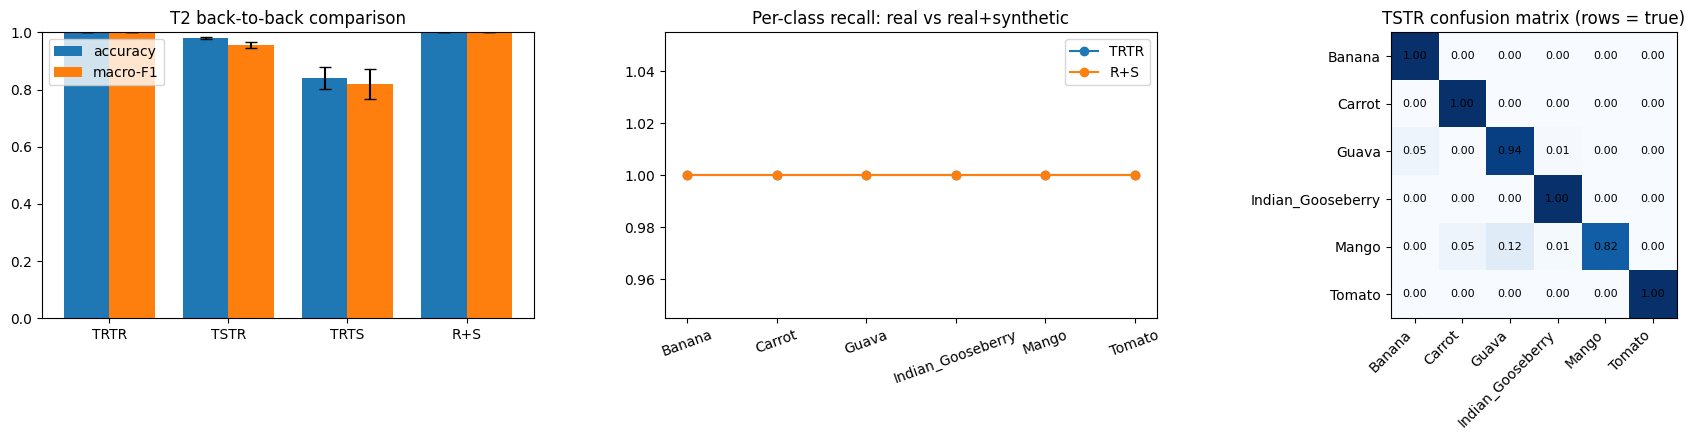

In [11]:
mean = res.groupby("variant")[["acc", "macro_f1"]].mean().reindex(order)
std = res.groupby("variant")[["acc", "macro_f1"]].std().reindex(order).fillna(0)

fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
xs = np.arange(len(order)); w = 0.38
ax[0].bar(xs - w/2, mean.acc, w, yerr=std.acc, capsize=4, label="accuracy")
ax[0].bar(xs + w/2, mean.macro_f1, w, yerr=std.macro_f1, capsize=4, label="macro-F1")
ax[0].set_xticks(xs); ax[0].set_xticklabels(order); ax[0].set_ylim(0, 1); ax[0].legend(); ax[0].set_title("T2 back-to-back comparison")

rec = res.groupby("variant")[[f"recall_{c}" for c in CLASSES]].mean()
for v in ["TRTR", "R+S"]:
    ax[1].plot(CLASSES, rec.loc[v].values, "o-", label=v)
ax[1].set_title("Per-class recall: real vs real+synthetic"); ax[1].legend(); ax[1].tick_params(axis="x", rotation=20)

cm = confusion_matrix(yte, preds_store[("TSTR", CLS_SEEDS[0])], labels=range(NC), normalize="true")
ax[2].imshow(cm, cmap="Blues", vmin=0, vmax=1)
ax[2].set_xticks(range(NC)); ax[2].set_xticklabels(CLASSES, rotation=45, ha="right"); ax[2].set_yticks(range(NC)); ax[2].set_yticklabels(CLASSES)
for i in range(NC):
    for j in range(NC): ax[2].text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center", fontsize=8)
ax[2].set_title("TSTR confusion matrix (rows = true)")
plt.tight_layout(); plt.savefig(OUT / "t2_back_to_back.png", dpi=120); plt.show()

acc = mean.acc; f1m = mean.macro_f1
T2a = acc["TSTR"] >= 0.70 * acc["TRTR"]
T2b = acc["TRTS"] >= 0.70
T2c = f1m["R+S"] >= f1m["TRTR"] - 0.01

---
# Test report

In [12]:
report = pd.DataFrame([
    ["T1a", "FID: model vs untrained G", f"{fid_model:.1f} < 0.5 × {fid_untrained:.1f}", T1a],
    ["T1b", "FID: class uniformity", f"max {per_class_fid.FID_generated.max():.1f} ≤ 2 × min {per_class_fid.FID_generated.min():.1f}", T1b],
    ["T2a", "TSTR utility ratio", f"{acc['TSTR']:.3f} / {acc['TRTR']:.3f} = {acc['TSTR']/acc['TRTR']:.2f} ≥ 0.70", T2a],
    ["T2b", "TRTS class correctness", f"{acc['TRTS']:.3f} ≥ 0.70", T2b],
    ["T2c", "Augmentation non-regression", f"F1 {f1m['R+S']:.3f} ≥ {f1m['TRTR']:.3f} − 0.01", T2c],
], columns=["id", "test", "measured", "pass"])
report["result"] = report["pass"].map({True: "PASS", False: "FAIL"})
display(report.drop(columns="pass"))

json.dump({
    "fid": {"floor_real_vs_real": fid_floor, "model": fid_model, "untrained": fid_untrained, "best_during_training": best_fid,
            "per_class": per_class_fid.to_dict("records"), "history": fid_hist},
    "back_to_back": res.to_dict("records"),
    "report": report.drop(columns="pass").to_dict("records"),
    "config": {"framework": f"tensorflow {tf.__version__}", "GAN_EPOCHS": GAN_EPOCHS, "CLS_EPOCHS": CLS_EPOCHS,
               "CLS_SEEDS": CLS_SEEDS, "IMG": IMG, "QUICK": QUICK},
}, open(OUT / "test_results.json", "w"), indent=2, default=float)
print("Saved figures + test_results.json + generator_best.keras to", OUT)

# release GPU memory so the session shuts down cleanly
keras.backend.clear_session(); _ = gc.collect()

,id,test,measured,result
0,T1a,FID: model vs untrained G,176.9 < 0.5 × 413.9,PASS
1,T1b,FID: class uniformity,max 304.8 ≤ 2 × min 159.8,PASS
2,T2a,TSTR utility ratio,0.979 / 1.000 = 0.98 ≥ 0.70,PASS
3,T2b,TRTS class correctness,0.840 ≥ 0.70,PASS
4,T2c,Augmentation non-regression,F1 1.000 ≥ 1.000 − 0.01,PASS


Saved figures + test_results.json + generator_best.keras to /kaggle/working/gan_testing


* **T1 (FID):** the gap between *generated* and the *real floor* is how far the GAN is from real data. Per-class gaps show
  which produce types the GAN serves poorly. These are usually the minority classes, which is the GAN-amplifies-imbalance bias risk.
* **T2 (back-to-back):** TSTR well below TRTR means the synthetic images look plausible but miss grading-relevant
  detail. If **R+S** raises recall on Banana and Mango without lowering macro-F1, GAN augmentation is worth shipping
  in SentraGrade. If it regresses (T2c FAIL), the test has stopped a harmful change before deployment, which is the point of the test.
* Caveat: FID here uses Keras InceptionV3 on 64×64 images upsampled to 299, so absolute values are not comparable with
  published FID numbers. Only the relative comparisons inside this notebook are meaningful.